## Exploratory data analysis

EDA of the four main datasets after cleaning. Figures are sized for the IEEE two-column format (3.5 in for one column, 7.16 in for full width) and saved to `results/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

PROCESSED = Path("../data/processed")
FIGURES = Path("../results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
CUTOFF = {"toddler": 3, "child": 6, "adolescent": 6, "adult": 6}

data = {g: pd.read_csv(PROCESSED / f"{g}.csv") for g in GROUPS}
for df in data.values():
    df["class"] = df["asd"].map({0: "No ASD traits", 1: "ASD traits"})

#### Figure style

In [2]:
COLUMN, PAGE = 3.5, 7.16  # IEEE widths in inches
COLORS = {"No ASD traits": "#8fb3d1", "ASD traits": "#d9775f"}
CLASSES = list(COLORS)
HANDLES = [plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in COLORS.items()]

sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

### 1. Class balance

In [3]:
counts = pd.DataFrame({g: df["class"].value_counts() for g, df in data.items()}).T[CLASSES]
counts["% ASD traits"] = (100 * counts["ASD traits"] / counts[CLASSES].sum(axis=1)).round(1)
counts

class,No ASD traits,ASD traits,% ASD traits
toddler,283,690,70.9
child,147,133,47.5
adolescent,41,60,59.4
adult,506,185,26.8


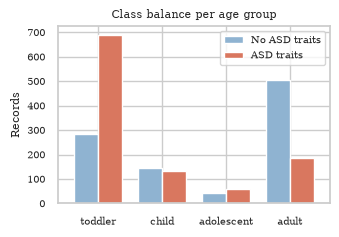

In [4]:
fig, ax = plt.subplots(figsize=(COLUMN, 2.3))
counts[CLASSES].plot.bar(ax=ax, color=list(COLORS.values()), rot=0, width=0.75)
ax.set_title("Class balance per age group")
ax.set_ylabel("Records")
ax.set_xlabel("")
ax.legend(title=None)
save(fig, "fig_class_balance")

The groups are imbalanced in different directions: most toddlers screened positive, most adults did not. The adolescent set is very small (about 100 rows), so its results will vary the most.

### 2. Age

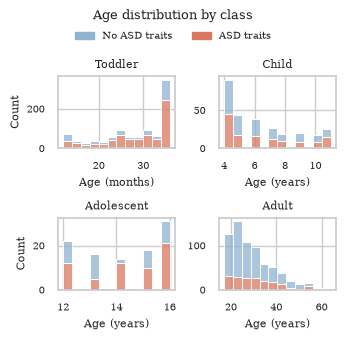

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.2))
for i, (ax, (g, df)) in enumerate(zip(axes.flat, data.items())):
    sns.histplot(df, x="age", hue="class", hue_order=CLASSES, palette=COLORS,
                 multiple="stack", bins=12, ax=ax, legend=False)
    ax.set_title(g.capitalize())
    ax.set_xlabel("Age (months)" if g == "toddler" else "Age (years)")
    ax.set_ylabel("Count" if i % 2 == 0 else "")
fig.suptitle("Age distribution by class", y=1.04)
fig.legend(handles=HANDLES, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "fig_age")

### 3. Questionnaire score

The score is the sum of A1–A10. The dashed line marks the cut-off used by the app.

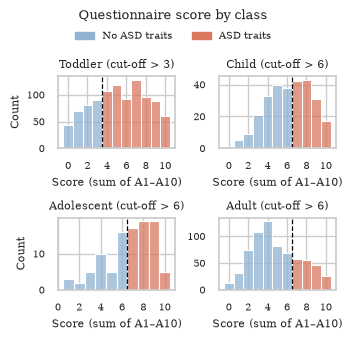

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.2))
for i, (ax, (g, df)) in enumerate(zip(axes.flat, data.items())):
    sns.histplot(df, x="score", hue="class", hue_order=CLASSES, palette=COLORS,
                 discrete=True, multiple="stack", ax=ax, legend=False)
    ax.axvline(CUTOFF[g] + 0.5, ls="--", lw=0.9, color="black")
    ax.set_title(f"{g.capitalize()} (cut-off > {CUTOFF[g]})")
    ax.set_xlabel("Score (sum of A1–A10)")
    ax.set_ylabel("Count" if i % 2 == 0 else "")
    ax.set_xticks(range(0, 11, 2))
fig.suptitle("Questionnaire score by class", y=1.04)
fig.legend(handles=HANDLES, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "fig_score_distribution")

The two colours never overlap: everything right of the line is "ASD traits". This is the leakage problem from notebook 02 shown as a picture. The class is a hard threshold on the sum of the ten inputs.

### 4. Answers by class

Share of people who scored 1 on each question, split by class.

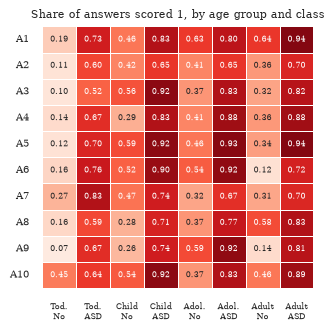

In [7]:
rates = pd.concat({g: df.groupby("asd")[QUESTIONS].mean().T for g, df in data.items()}, axis=1)
SHORT = {"toddler": "Tod.", "child": "Child", "adolescent": "Adol.", "adult": "Adult"}
rates.columns = [f"{SHORT[g]}\n{'ASD' if c else 'No'}" for g, c in rates.columns]

fig, ax = plt.subplots(figsize=(COLUMN, 3.4))
sns.heatmap(rates, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="Reds", vmin=0, vmax=1,
            cbar=False, linewidths=0.4, ax=ax)
ax.set_title("Share of answers scored 1, by age group and class")
ax.tick_params(axis="x", rotation=0, labelsize=6)
ax.tick_params(axis="y", rotation=0)
save(fig, "fig_answer_rates")

Remember that the AQ-10 wording differs between child, adolescent and adult, so the same row is not always the same question across columns.

### 5. Chi-square test

The proposal plans a chi-square test of each input against the label. With ~100–1,000 rows almost every question comes out highly significant, so the chi-square value is more useful for comparing questions than the p-value.

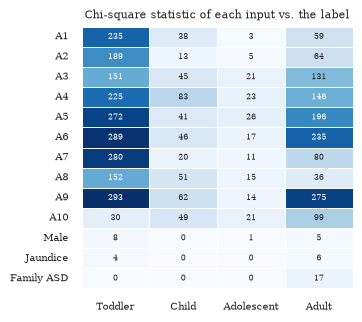

In [8]:
FEATURE_NAMES = {"male": "Male", "jaundice": "Jaundice", "family_asd": "Family ASD"}

rows = []
for g, df in data.items():
    for col in QUESTIONS + list(FEATURE_NAMES):
        chi2, p, _, _ = chi2_contingency(pd.crosstab(df[col], df["asd"]))
        rows.append({"group": g, "feature": col, "chi2": chi2, "p": p})
chi = pd.DataFrame(rows)

table = chi.pivot(index="feature", columns="group", values="chi2")[GROUPS]
table = table.loc[QUESTIONS + list(FEATURE_NAMES)].rename(index=FEATURE_NAMES)
table.columns = [g.capitalize() for g in GROUPS]

fig, ax = plt.subplots(figsize=(COLUMN, 3.4))
sns.heatmap(table, annot=True, fmt=".0f", annot_kws={"size": 6}, cmap="Blues", cbar=False,
            linewidths=0.4, ax=ax)
ax.set_title("Chi-square statistic of each input vs. the label")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
save(fig, "fig_chi_square")

In [9]:
# personal details: are they related to the label at all? (p-values)
chi[chi.feature.isin(FEATURE_NAMES)].pivot(index="feature", columns="group", values="p")[GROUPS].round(3)

group,toddler,child,adolescent,adult
feature,,,,
family_asd,0.828,0.576,1.000,0.000
jaundice,0.056,0.984,0.998,0.017
male,0.006,0.614,0.290,0.030


### 6. Relationships between questions

Correlation between the ten answers (for 0/1 data this is the phi coefficient).

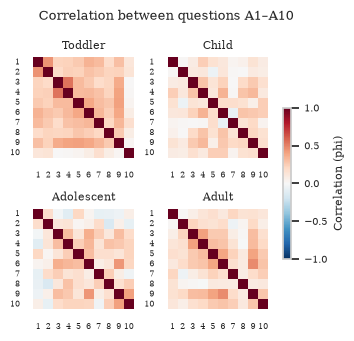

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 3.4))
for ax, (g, df) in zip(axes.flat, data.items()):
    sns.heatmap(df[QUESTIONS].corr(), ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, cbar=False, square=True,
                xticklabels=[q[1:] for q in QUESTIONS], yticklabels=[q[1:] for q in QUESTIONS])
    ax.set_title(g.capitalize())
    ax.tick_params(labelsize=6, rotation=0)
fig.suptitle("Correlation between questions A1–A10")
fig.tight_layout()
fig.colorbar(axes[0, 0].collections[0], ax=axes, shrink=0.6, label="Correlation (phi)")
save(fig, "fig_question_correlation")

### 7. Personal details

Share of "ASD traits" (%) within each category.

In [11]:
details = {}
for g, df in data.items():
    details[g] = {
        "male": df.loc[df.male == 1, "asd"].mean(),
        "female": df.loc[df.male == 0, "asd"].mean(),
        "jaundice": df.loc[df.jaundice == 1, "asd"].mean(),
        "no jaundice": df.loc[df.jaundice == 0, "asd"].mean(),
        "family history": df.loc[df.family_asd == 1, "asd"].mean(),
        "no family history": df.loc[df.family_asd == 0, "asd"].mean(),
    }
(pd.DataFrame(details) * 100).round(1)

,toddler,child,adolescent,adult
male,73.6,48.7,53.1,23.1
female,64.6,44.6,65.4,30.7
jaundice,75.5,46.8,56.2,39.7
no jaundice,69.1,47.8,60.0,25.4
family history,69.9,42.9,57.1,45.5
no family history,71.1,48.5,59.8,24.0


### Summary

* **Balance.** Toddlers are 71 % positive, children about 50/50, adolescents 59 %, adults only 27 %.
* **Score.** The classes are perfectly separated at the cut-off in every group, confirming that the label is the scoring rule.
* **Questions.** In the adult data A6 and A9 separate the classes most clearly (about 0.13 vs 0.75), while A1 and A8 are often scored 1 by both classes. For toddlers, A10 is scored 1 by almost half of the "no ASD" group, so it separates the classes least. These differences are what the explanation methods pick up in notebook 07.
* **Personal details.** In adults, family history (46 % vs 24 %) and jaundice (40 % vs 25 %) are linked to a positive screen; in toddlers, boys screen positive more often (74 % vs 65 %). For children and adolescents there is no clear link. These details can only matter to the model where the questions alone leave doubt, which here is never.

| File | Suggested size in the paper |
|---|---|
| `fig_class_balance` | one column |
| `fig_age` | one column |
| `fig_score_distribution` | one column |
| `fig_answer_rates` | one column |
| `fig_chi_square` | one column |
| `fig_question_correlation` | one column |